In [23]:
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.metrics import accuracy_score, log_loss, roc_auc_score
import lightgbm as lgb


In [24]:
PROCESSED_DIR = Path("../data/processed")

train_df = pd.read_csv(PROCESSED_DIR / "train.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test.csv")

In [25]:
FEATURE_COLS = [
    # contesto partita
    "surface",
    "tourney_level",
    "best_of",
    
    # età
    "player_age",
    "opponent_age",
    "age_diff",
    
    # ranking assoluto + differenza log
    "player_rank",
    "opponent_rank",
    "rank_log_diff",
    "rank_log_points_diff",
    
    # elo generale assoluto + differenza
    "player_elo",
    "opponent_elo",
    "elo_diff",
    
    # elo surface assoluto + differenza
    "player_surface_elo",
    "opponent_surface_elo",
    "surface_elo_diff",
    
    # recent form
    "player_recent_form",
    "opponent_recent_form",
    "recent_form_diff",
    
    # volume forma recente
    "player_recent_matches",
    "opponent_recent_matches",
    "recent_matches_diff",
    
    # rilevanza superficie nella forma recente
    "player_surface_relevance",
    "opponent_surface_relevance",
    "surface_relevance_diff",
]


TARGET_COL = "target"

In [26]:
X_train = train_df[FEATURE_COLS]
y_train = train_df[TARGET_COL]

X_test = test_df[FEATURE_COLS]
y_test = test_df[TARGET_COL]

In [27]:
categorical_cols = ["surface", "tourney_level"]

for col in categorical_cols:
    X_train[col] = X_train[col].astype("category")
    X_test[col] = X_test[col].astype("category")

In [28]:
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", "passthrough", numeric_cols),
    ]
)

In [46]:
model = lgb.LGBMClassifier(
    objective="binary",
    metric = "binary_logloss",
    n_estimators= 2000,
    learning_rate= 0.02,
    max_depth=6,
    num_leaves=31,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state = 42
)

In [47]:
model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[
        lgb.early_stopping(50),      # stop se non migliora per 50 rounds
        lgb.log_evaluation(100)       # stampa progress ogni 100 alberi
    ]
)

[LightGBM] [Info] Number of positive: 114146, number of negative: 114146
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001821 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4751
[LightGBM] [Info] Number of data points in the train set: 228292, number of used features: 25
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
Training until validation scores don't improve for 50 rounds
[100]	valid_0's binary_logloss: 0.60648
[200]	valid_0's binary_logloss: 0.599774
[300]	valid_0's binary_logloss: 0.598418
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[400]	valid_0's binary_logloss: 0.597949
[LightGBM] [Warning] No further splits with p

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,6
,learning_rate,0.02
,n_estimators,2000
,subsample_for_bin,200000
,objective,'binary'
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [48]:
test_pred_proba = model.predict_proba(X_test)[:, 1]
test_pred = (test_pred_proba >= 0.5).astype(int)

In [49]:
acc = accuracy_score(y_test, test_pred)
ll = log_loss(y_test, test_pred_proba)
auc = roc_auc_score(y_test, test_pred_proba)

acc, ll, auc

(0.6666666666666666, 0.5977668277461737, 0.7379613042163053)

In [36]:
baseline_proba = 1.0 / (1.0 + 10 ** (-test_df["elo_diff"] / 400.0))
baseline_pred = (baseline_proba >= 0.5).astype(int)

baseline_acc = accuracy_score(y_test, baseline_pred)
baseline_ll = log_loss(y_test, baseline_proba)
baseline_auc = roc_auc_score(y_test, baseline_proba)

baseline_acc, baseline_ll, baseline_auc

(0.648808536517941, 0.6199797768217666, 0.7132386941550322)

In [38]:
pd.DataFrame({
    "metric": ["accuracy", "log_loss", "auc"],
    "elo_baseline": [baseline_acc, baseline_ll, baseline_auc],
    "lgbm_model": [acc, ll, auc],
})

,metric,elo_baseline,lgbm_model
0,accuracy,0.648809,0.667745
1,log_loss,0.619980,0.597911
2,auc,0.713239,0.737858


In [50]:
import shap

# TreeExplainer è ottimizzato specificamente per modelli ad albero
# è molto più veloce dell'Explainer generico
explainer = shap.TreeExplainer(model)

# calcola i valori SHAP per tutto il test set
# questo può richiedere qualche secondo
shap_values = explainer(X_test)

Matplotlib is building the font cache; this may take a moment.


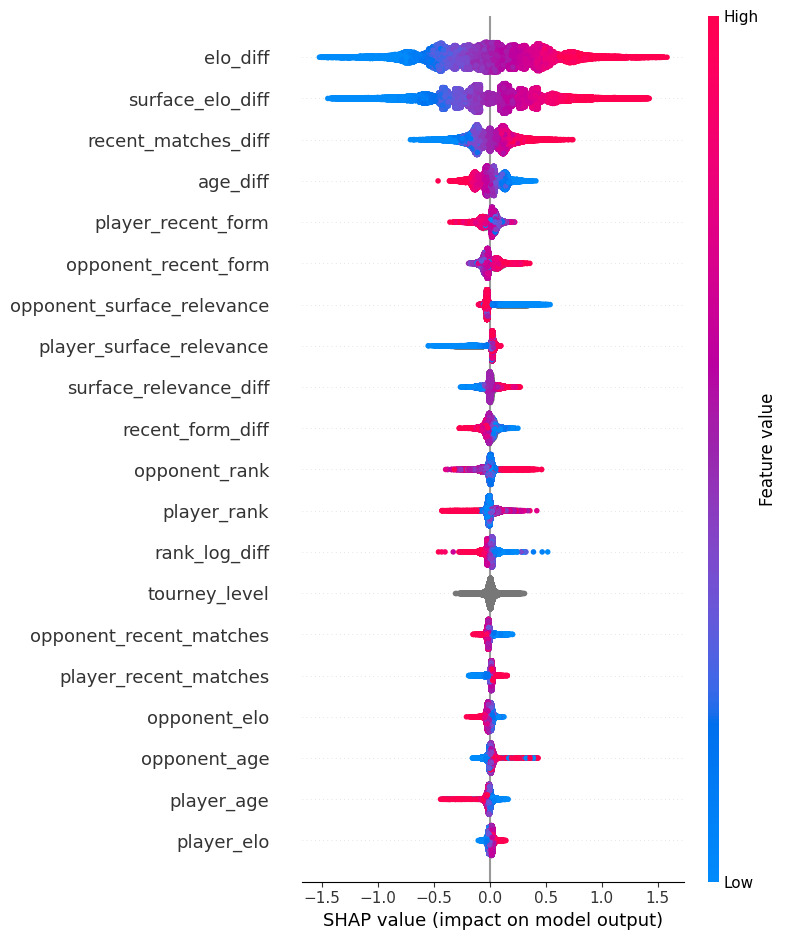

In [51]:
# summary plot — mostra importanza globale di tutte le feature
# ogni punto è una partita del test set
# colore rosso = valore alto della feature, blu = valore basso
# posizione sull'asse X = quanto ha spinto la predizione verso 1 o 0
shap.summary_plot(shap_values, X_test)